# CS781 Phase 1 — Notebook 1: Data inspection, tokenizer, local evaluation set

**What this notebook produces** (everything is under `cs781_p1/`, which is saved on Kaggle commit / in Drive on Colab):

| Folder | Content | Used by |
|---|---|---|
| `data/` | per-source statistics, duplicate lists, `decisions.json` (cleaning mode) | NB2, report |
| `tok_sample/` | balanced text sample used to train the tokenizer | this notebook |
| `tokenizer/bpe16384`, `bpe32768`, `bpe49152` | trained byte-level BPE tokenizers + `tokenizer_report.json` | NB2, training, generation |
| `eval/` | **local test-like set**: 512-word prompts + true 128-word continuations from held-out documents | every experiment |

**Pipeline in this notebook**
1. Look at the official test prompts (how long, do they contain newlines?) → decide how to clean training text so it *looks like* the test input.
2. One streaming pass over each training file (never loads a multi-GB file into RAM): statistics, exact-duplicate detection, document-level train/val split, a balanced sample for tokenizer training, and candidate evaluation windows from held-out docs.
3. Train byte-level BPE tokenizers at 3 vocabulary sizes and compare them (fertility = tokens per word, prompt length in tokens, round-trip exactness), plus the GPT-2 tokenizer the starter uses.
4. (Optional, educational) a from-scratch pure-Python BPE trainer, compared against the library's merges.
5. Build the local evaluation set and score two trivial baselines with the *exact* official metric code.

**Resuming**: every heavy step writes its result to disk and is skipped if the result already exists.
On Kaggle commit mode, a new run starts with an empty `/kaggle/working`; to resume, attach the previous version's output
(*Add Input → Your Work → this notebook*) and `restore_from_kaggle_inputs` copies it back.

**Settings**: Kaggle → Internet ON, Accelerator: None (CPU is enough). Secret named `HF` with your HF token.

In [1]:
!pip -q install ijson tokenizers huggingface_hub bert-score rouge-score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.0 MB/s eta 0:00:00


In [2]:
# ============================================================================================
# SHARED SETUP  —  paste this SAME cell at the top of every Phase-1 notebook.
# Works on Kaggle (Save & Commit or interactive), Colab (Drive) and local machines.
# ============================================================================================
import os, sys, json, time, glob, shutil, random, math, re, zlib, hashlib, gc
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np

os.environ.setdefault("TOKENIZERS_PARALLELISM", "true")

SESSION_START = time.time()
TIME_BUDGET_H = 11.0   # Kaggle kills a session at 12h and then saves NOTHING -> every long loop stops itself before this

IN_COLAB  = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/working")
PROJECT   = "cs781_p1"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT, SCRATCH = Path("/content/drive/MyDrive") / PROJECT, Path("/content/scratch")   # Drive = persistent
elif IN_KAGGLE:
    ROOT, SCRATCH = Path("/kaggle/working") / PROJECT, Path("/tmp/cs781_scratch")       # working = saved on commit
else:
    ROOT, SCRATCH = Path("./") / PROJECT, Path("./scratch")
ROOT    = Path(os.environ.get("CS781_ROOT", ROOT))
SCRATCH = Path(os.environ.get("CS781_SCRATCH", SCRATCH))
ROOT.mkdir(parents=True, exist_ok=True); SCRATCH.mkdir(parents=True, exist_ok=True)

ENV = "colab" if IN_COLAB else "kaggle" if IN_KAGGLE else "local"
print(f"env={ENV}  ROOT={ROOT}  SCRATCH={SCRATCH}")
for p in {ROOT, SCRATCH}:
    du = shutil.disk_usage(p); print(f"  disk @ {p}: free {du.free/1e9:.1f} GB / total {du.total/1e9:.1f} GB")


# ---------------------------------------------------------------- small utilities
def time_left_h():
    return TIME_BUDGET_H - (time.time() - SESSION_START) / 3600

def save_json(obj, path):
    """Atomic write: a crash mid-write can never leave a half-written (corrupt) state file."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=1)
    os.replace(tmp, path)

def load_json(path, default=None):
    path = Path(path)
    if not path.exists(): return default
    with open(path, encoding="utf-8") as f: return json.load(f)

def restore_from_kaggle_inputs(subdirs):
    """Kaggle 'Save & Commit' starts every run with an EMPTY /kaggle/working.
    To resume, attach the output of the previous version (Add Input -> Your Work -> Notebook output).
    This copies <PROJECT>/<subdir> from any attached input into ROOT (never overwriting newer local files)."""
    if not IN_KAGGLE: return
    for sub in subdirs:
        for cand in sorted(glob.glob(f"/kaggle/input/**/{PROJECT}/{sub}", recursive=True)):
            n = 0
            for src in Path(cand).rglob("*"):
                if src.is_file():
                    dst = ROOT / sub / src.relative_to(cand)
                    if not dst.exists():
                        dst.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(src, dst); n += 1
            print(f"restored {n} files: {cand} -> {ROOT/sub}")

def find_artifact(rel):
    """Look for ROOT/rel first, then inside any attached Kaggle input."""
    p = ROOT / rel
    if p.exists(): return p
    if IN_KAGGLE:
        hits = sorted(glob.glob(f"/kaggle/input/**/{PROJECT}/{rel}", recursive=True))
        if hits: return Path(hits[0])
    return None

def get_hf_token():
    if os.environ.get("HF_TOKEN"): return os.environ["HF_TOKEN"]
    try:
        if IN_KAGGLE:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret("HF")
        if IN_COLAB:
            from google.colab import userdata
            return userdata.get("HF")
    except Exception as e:
        print("Could not read secret 'HF':", e)
    return None

HF_TOKEN = get_hf_token()
if HF_TOKEN: os.environ["HF_TOKEN"] = HF_TOKEN
print("HF token found:", bool(HF_TOKEN))

# Optional: a PRIVATE HF dataset repo used only to move YOUR OWN artifacts between accounts/sessions.
HF_ARTIFACT_REPO = None   # e.g. "your-hf-username/cs781-p1-artifacts"

def hf_push(subdir):
    if not HF_ARTIFACT_REPO: print("HF_ARTIFACT_REPO not set; skip push"); return
    from huggingface_hub import HfApi
    api = HfApi(token=HF_TOKEN)
    api.create_repo(HF_ARTIFACT_REPO, repo_type="dataset", private=True, exist_ok=True)
    api.upload_folder(folder_path=str(ROOT / subdir), path_in_repo=subdir,
                      repo_id=HF_ARTIFACT_REPO, repo_type="dataset")
    print("pushed", subdir)

def hf_pull(subdir):
    if not HF_ARTIFACT_REPO: return
    from huggingface_hub import snapshot_download
    snapshot_download(HF_ARTIFACT_REPO, repo_type="dataset", allow_patterns=[f"{subdir}/*", f"{subdir}/**"],
                      local_dir=str(ROOT), token=HF_TOKEN)
    print("pulled", subdir)


# ---------------------------------------------------------------- data utilities
# These MUST be identical in every notebook (the train/val split and cleaning depend on them).
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
SOURCE_NAMES = ["acts", "high_courts", "supreme_court", "tribunals"]   # processing order (matters for dedup)
VAL_PER_10K  = 100            # 1% of documents of every source are held out (document-level split)
PROMPT_WORDS, CONT_WORDS = 512, 128

def extract_text(rec):
    if rec is None: return ""
    if isinstance(rec, str): return rec
    if isinstance(rec, list): return "\n".join(extract_text(r) for r in rec)
    if isinstance(rec, dict):
        for k in ("text", "content", "document", "judgment", "judgement", "body"):
            if k in rec: return extract_text(rec[k])
    return ""

def iter_docs(path):
    """Stream documents from a (possibly multi-GB) JSON file WITHOUT loading it all into RAM.
    Handles: [ {...}, ... ]   |   { id: {...}, ... }   |   JSON-lines."""
    import ijson
    with open(path, "rb") as f:
        head = f.read(1 << 16).lstrip()
        f.seek(0)
        if head[:1] == b"[":
            for rec in ijson.items(f, "item", use_float=True):
                yield extract_text(rec)
            return
        first_line = f.readline(50_000_000); second = f.read(1 << 10).lstrip()[:1]
        f.seek(0)
        is_jsonl = False
        if first_line.endswith(b"\n") and second == b"{":
            try: json.loads(first_line); is_jsonl = True
            except Exception: pass
        if is_jsonl:
            for line in f:
                if line.strip(): yield extract_text(json.loads(line))
        else:
            for _, rec in ijson.kvitems(f, "", use_float=True):
                yield extract_text(rec)

_ZW = re.compile(r"[​‌‍﻿­]")
_WS_ALL = re.compile(r"\s+")
_HSPACE = re.compile(r"[^\S\n]+")
_MANY_NL = re.compile(r"\n\s*\n\s*\n+")

def normalize(text, mode):
    """'collapse_all'  -> every whitespace run becomes one space (text looks like ' '.join(text.split()))
       'keep_newlines' -> collapse spaces/tabs, keep at most one blank line"""
    text = _ZW.sub("", text)
    if mode == "collapse_all":
        return _WS_ALL.sub(" ", text).strip()
    text = _HSPACE.sub(" ", text.replace("\r\n", "\n").replace("\r", "\n"))
    text = "\n".join(l.strip() for l in text.split("\n"))
    return _MANY_NL.sub("\n\n", text).strip()

def hash64(text):
    return int.from_bytes(hashlib.blake2b(text.encode("utf-8", "ignore"), digest_size=8).digest(), "little")

def doc_split(source, idx):
    return "val" if zlib.crc32(f"{source}:{idx}".encode()) % 10000 < VAL_PER_10K else "train"

def list_phase1_files(local_raw_dir=None):
    """Return {'train': {source: repo_path}, 'test': repo_path, 'sizes': {repo_path: bytes}}."""
    if local_raw_dir:
        files = [str(Path(p).relative_to(local_raw_dir)) for p in glob.glob(f"{local_raw_dir}/**/*.json*", recursive=True)]
        sizes = {f: os.path.getsize(Path(local_raw_dir) / f) for f in files}
    else:
        from huggingface_hub import HfApi
        api = HfApi(token=HF_TOKEN)
        try:
            entries = list(api.list_repo_tree(HF_DATASET_REPO, repo_type="dataset",
                                              path_in_repo="Phase_1_Pretraining", recursive=True))
            files = [e.path for e in entries if getattr(e, "size", None) is not None]
            sizes = {e.path: e.size for e in entries if getattr(e, "size", None) is not None}
        except Exception as e:
            print("list_repo_tree failed (", e, ") -> falling back to list_repo_files")
            files = [f for f in api.list_repo_files(HF_DATASET_REPO, repo_type="dataset") if f.startswith("Phase_1")]
            sizes = {}
    out = {"train": {}, "test": None, "sizes": sizes}
    for f in files:
        name = Path(f).name.lower()
        if not name.endswith((".json", ".jsonl")): continue
        if "test" in name: out["test"] = f
        for s in SOURCE_NAMES:
            if name.startswith("train") and s in name: out["train"][s] = f
    return out

def get_raw_file(repo_path, local_raw_dir=None):
    if local_raw_dir:
        return Path(local_raw_dir) / repo_path
    from huggingface_hub import hf_hub_download
    return Path(hf_hub_download(HF_DATASET_REPO, repo_path, repo_type="dataset", token=HF_TOKEN,
                                local_dir=str(SCRATCH / "raw")))

def drop_raw_file(path, local_raw_dir=None):
    if local_raw_dir: return          # never delete user-provided files
    try: os.remove(path); print("deleted raw", path)
    except OSError: pass

env=kaggle  ROOT=/kaggle/working/cs781_p1  SCRATCH=/tmp/cs781_scratch
  disk @ /tmp/cs781_scratch: free 1201.7 GB / total 8758.4 GB
  disk @ /kaggle/working/cs781_p1: free 20.9 GB / total 21.0 GB
HF token found: True


## 1. Configuration

In [3]:
LOCAL_RAW_DIR = os.environ.get("CS781_LOCAL_RAW")   # None -> download from Hugging Face. Set to a folder if you already have the files.

TOK_SAMPLE_MB_PER_SOURCE   = 150      # tokenizer training text per source (~600 MB total). BPE merges saturate long before using all data.
EVAL_CANDIDATES_PER_SOURCE = 400      # reservoir of held-out windows kept per source
EVAL_PER_SOURCE            = 100      # final local eval set = 4 x 100 = 400 examples
NORMALIZE_MODE             = "auto"   # "auto" | "collapse_all" | "keep_newlines"
TOKENIZER_VOCAB_SIZES      = [16384, 32768, 49152]   # multiples of 64 (GPU friendly) and < 65536 (fits uint16)
MAIN_VOCAB                 = 32768
SPECIAL_TOKENS = ["<|endoftext|>", "<|pad|>", "<|bos|>", "<|sep|>", "<|mask|>"] + [f"<|reserved_{i}|>" for i in range(11)]
RUN_SCRATCH_BPE            = True     # educational from-scratch BPE comparison (~5 min)
RUN_BERTSCORE_BASELINES    = True     # downloads roberta-large (the official BERTScore model) ~1.4 GB
SEED = 42

for d in ["data", "tok_sample", "tokenizer", "eval", "figures"]:
    (ROOT / d).mkdir(parents=True, exist_ok=True)
restore_from_kaggle_inputs(["data", "tok_sample", "tokenizer", "eval", "figures"])

## 2. What is in the dataset?
List the Phase-1 files and their sizes before downloading anything.

In [4]:
FILES = list_phase1_files(LOCAL_RAW_DIR)
print("train files:")
for s, f in FILES["train"].items():
    print(f"  {s:14s} {f:60s} {FILES['sizes'].get(f, 0)/1e9:7.2f} GB")
print("test file:", FILES["test"], f"{FILES['sizes'].get(FILES['test'], 0)/1e6:.1f} MB")
assert len(FILES["train"]) == 4 and FILES["test"], "could not find all Phase-1 files — check names above"
save_json(FILES, ROOT / "data" / "files.json")

train files:
  acts           Phase_1_Pretraining/Train/train_acts.json                       0.73 GB
  high_courts    Phase_1_Pretraining/Train/train_high_courts.json               10.67 GB
  supreme_court  Phase_1_Pretraining/Train/train_supreme_court.json              1.32 GB
  tribunals      Phase_1_Pretraining/Train/train_tribunals.json                  6.48 GB
test file: Phase_1_Pretraining/Test/test.json 3.0 MB


## 3. The official test prompts
The model will be *conditioned* on these, so training text should look like them. Key questions:
exact word counts, whether newlines survive (if not, we collapse all whitespace in training data too),
and how prompts end (mid-sentence? → the continuation starts mid-sentence).

In [5]:
test_path = get_raw_file(FILES["test"], LOCAL_RAW_DIR)
with open(test_path, encoding="utf-8") as f:
    test_raw = json.load(f)
if isinstance(test_raw, list):     # tolerate a list format, though the spec says {id: {"text": ...}}
    test_raw = {str(r.get("id", i)): r for i, r in enumerate(test_raw)}
TEST_IDS   = list(test_raw.keys())
TEST_TEXTS = [extract_text(test_raw[i]) for i in TEST_IDS]   # raw, exactly as given
wc = np.array([len(t.split()) for t in TEST_TEXTS])
nl_frac = float(np.mean(["\n" in t for t in TEST_TEXTS]))
dbl_space_frac = float(np.mean(["  " in t for t in TEST_TEXTS]))
ends_sentence = float(np.mean([t.rstrip()[-1:] in ".?!:;\"')" for t in TEST_TEXTS]))
print(f"#test prompts: {len(TEST_IDS)}   id examples: {TEST_IDS[:5]}")
print(f"words/prompt: min {wc.min()}  mean {wc.mean():.1f}  max {wc.max()}")
print(f"prompts containing newline: {nl_frac:.1%}   containing double spaces: {dbl_space_frac:.1%}")
print(f"prompts ending at sentence punctuation: {ends_sentence:.1%}")
for t in TEST_TEXTS[:3]:
    print("\n--- START:", t[:400].replace("\n", "⏎"), "\n--- END:  ...", t[-250:].replace("\n", "⏎"))

if NORMALIZE_MODE == "auto":
    NORM = "collapse_all" if nl_frac < 0.05 else "keep_newlines"
else:
    NORM = NORMALIZE_MODE
print("\n==> text normalisation used for ALL training data (and applied to test prompts at generation):", NORM)
TEST_NORM = [normalize(t, NORM) for t in TEST_TEXTS]

decisions = load_json(ROOT / "data" / "decisions.json", {})
if decisions.get("normalize") and decisions["normalize"] != NORM:
    raise RuntimeError("normalisation differs from an earlier run; delete data/ & tok_sample/ to redo")
decisions.update({"normalize": NORM, "n_test": len(TEST_IDS), "test_words_mean": float(wc.mean()),
                  "test_newline_frac": nl_frac, "test_ends_sentence_frac": ends_sentence})
save_json(decisions, ROOT / "data" / "decisions.json")

test.json: 0.00B [00:00, ?B/s]

#test prompts: 1000   id examples: ['1', '2', '3', '4', '5']
words/prompt: min 512  mean 512.0  max 512
prompts containing newline: 0.0%   containing double spaces: 0.0%
prompts ending at sentence punctuation: 4.5%

--- START: The issue involved in these petitions is as to whether the acquisition proceedings can be challenged at a belated stage. The issue is no more res integra as the issue has been considered by this Court time and again. 6. When a person challenges Section 4 Notification on any ground, it should be challenged within a reasonable period, and if the acquisition is challenged at a belated stage, the peti 
--- END:  ... ot approached the Court within reasonable time, as judicial review is not permissible at a belated stage. This Court held as under: " Delay in challenging the notification was fatal and writ petition entails with dismissal on grounds of laches. It is

--- START: Instead of taking cognizance of the offence, he has, in the exercise of his discretion, sent t

## 4. One streaming pass over every training file
Per document: clean (same as test) → count words → exact-duplicate check (64-bit hash of cleaned text) →
document-level split (1% val, decided by a hash of `source:index`, so NB2 reproduces it exactly) →
- train docs: sampled into `tok_sample/<source>.jsonl` with probability ≈ 150 MB / file size
- val docs with ≥ 640 words: reservoir-sampled evaluation windows (both "document start" and "random position")

A file is marked done only after all its outputs are written, so a crash just redoes that one file.

In [6]:
WORD_RE = re.compile(r"\S+")

def make_window(text, start_word):
    """Prompt = 512 words, reference = next 128 words, cut from the ORIGINAL (cleaned) text so spacing is kept."""
    spans = []
    for m in WORD_RE.finditer(text):
        spans.append(m.span())
        if len(spans) >= start_word + PROMPT_WORDS + CONT_WORDS: break
    p0, p1 = spans[start_word][0], spans[start_word + PROMPT_WORDS - 1][1]
    r0, r1 = spans[start_word + PROMPT_WORDS][0], spans[start_word + PROMPT_WORDS + CONT_WORDS - 1][1]
    return text[p0:p1], text[r0:r1]

def process_source(name, repo_path, seen_hashes):
    raw_path = get_raw_file(repo_path, LOCAL_RAW_DIR)
    fsize = os.path.getsize(raw_path)
    p_sample = min(1.0, TOK_SAMPLE_MB_PER_SOURCE * 1e6 / max(fsize, 1))
    rng = random.Random(f"{SEED}-{name}")
    wordcounts, hashes, dups, reservoir = [], [], [], []
    stats = Counter(); samples_raw = []
    t0 = time.time()
    tmp_sample = ROOT / "tok_sample" / f"{name}.jsonl.partial"
    with open(tmp_sample, "w", encoding="utf-8") as fs:
        for idx, raw in enumerate(iter_docs(raw_path)):
            if idx < 3: samples_raw.append(raw[:600])
            stats["docs"] += 1
            stats["raw_has_newline"] += ("\n" in raw)
            text = normalize(raw, NORM)
            nw = len(text.split())
            wordcounts.append(nw)
            if nw == 0:
                stats["empty"] += 1; hashes.append(0); continue
            h = hash64(text); hashes.append(h)
            if h in seen_hashes:
                stats["duplicates"] += 1; dups.append(idx); continue
            seen_hashes.add(h)
            stats["words"] += nw; stats["chars"] += len(text)
            if doc_split(name, idx) == "train":
                stats["train_docs"] += 1; stats["train_words"] += nw
                if rng.random() < p_sample:
                    fs.write(json.dumps({"text": text}, ensure_ascii=False) + "\n"); stats["sampled_docs"] += 1
            else:
                stats["val_docs"] += 1; stats["val_words"] += nw
                if nw >= PROMPT_WORDS + CONT_WORDS:
                    stats["val_docs_long"] += 1
                    m = stats["val_docs_long"]
                    slot = len(reservoir) if len(reservoir) < EVAL_CANDIDATES_PER_SOURCE else rng.randrange(m)
                    if slot < EVAL_CANDIDATES_PER_SOURCE:
                        sp, sr = make_window(text, 0)
                        rs = rng.randrange(0, nw - PROMPT_WORDS - CONT_WORDS + 1)
                        rp, rr = make_window(text, rs)
                        item = {"source": name, "doc_idx": idx, "doc_words": nw,
                                "start_prompt": sp, "start_ref": sr, "rand_prompt": rp, "rand_ref": rr, "rand_start": rs}
                        if slot == len(reservoir): reservoir.append(item)
                        else: reservoir[slot] = item
            if idx % 50000 == 0 and idx:
                el = time.time() - t0
                print(f"  [{name}] {idx:,} docs  {stats['words']/1e6:,.0f}M words  {idx/el:,.0f} docs/s  {el/60:.1f} min")
    os.replace(tmp_sample, ROOT / "tok_sample" / f"{name}.jsonl")
    np.save(ROOT / "data" / f"{name}_wordcounts.npy", np.array(wordcounts, dtype=np.int32))
    np.save(ROOT / "data" / f"{name}_hashes.npy", np.array(hashes, dtype=np.uint64))
    np.save(ROOT / "data" / f"{name}_dups.npy", np.array(dups, dtype=np.int64))
    save_json(reservoir, ROOT / "eval" / f"candidates_{name}.json")
    stats = dict(stats); stats.update({"file_bytes": fsize, "p_sample": p_sample, "seconds": time.time() - t0,
                                       "raw_samples": samples_raw, "repo_path": repo_path})
    save_json(stats, ROOT / "data" / f"{name}_stats.json")
    drop_raw_file(raw_path, LOCAL_RAW_DIR)
    return stats

state = load_json(ROOT / "data" / "pass1_state.json", {"done": []})
seen = set()
for name in SOURCE_NAMES:                      # rebuild the global dedup set from finished sources
    if name in state["done"]:
        seen.update(int(h) for h in np.load(ROOT / "data" / f"{name}_hashes.npy") if h != 0)
for name in SOURCE_NAMES:
    if name in state["done"]:
        print(f"[{name}] already done — skipping"); continue
    if time_left_h() < 1.0:
        print("Not enough session time left; re-run (with this output attached) to continue."); break
    print(f"[{name}] processing {FILES['train'][name]} ...")
    st = process_source(name, FILES["train"][name], seen)
    state["done"].append(name); save_json(state, ROOT / "data" / "pass1_state.json")
    print(f"[{name}] done: {st['docs']:,} docs, {st['words']/1e6:,.1f}M words, {st['duplicates']:,} dups, {st['seconds']/60:.1f} min")
PASS1_COMPLETE = len(state["done"]) == len(SOURCE_NAMES)
print("pass 1 complete:", PASS1_COMPLETE)

[acts] processing Phase_1_Pretraining/Train/train_acts.json ...


Phase_1_Pretraining/Train/train_acts.jso(…):   0%|          | 0.00/729M [00:00<?, ?B/s]

deleted raw /tmp/cs781_scratch/raw/Phase_1_Pretraining/Train/train_acts.json
[acts] done: 18,826 docs, 119.3M words, 91 dups, 1.1 min
[high_courts] processing Phase_1_Pretraining/Train/train_high_courts.json ...


Phase_1_Pretraining/Train/train_high_cou(…):   0%|          | 0.00/10.7G [00:00<?, ?B/s]

  [high_courts] 50,000 docs  21M words  3,798 docs/s  0.2 min
  [high_courts] 100,000 docs  42M words  3,948 docs/s  0.4 min
  [high_courts] 150,000 docs  63M words  4,041 docs/s  0.6 min
  [high_courts] 200,000 docs  84M words  4,066 docs/s  0.8 min
  [high_courts] 250,000 docs  104M words  3,870 docs/s  1.1 min
  [high_courts] 300,000 docs  123M words  3,849 docs/s  1.3 min
  [high_courts] 350,000 docs  141M words  3,905 docs/s  1.5 min
  [high_courts] 400,000 docs  156M words  4,034 docs/s  1.7 min
  [high_courts] 450,000 docs  172M words  4,087 docs/s  1.8 min
  [high_courts] 550,000 docs  205M words  3,729 docs/s  2.5 min
  [high_courts] 600,000 docs  232M words  3,685 docs/s  2.7 min
  [high_courts] 650,000 docs  263M words  3,442 docs/s  3.1 min
  [high_courts] 700,000 docs  291M words  2,913 docs/s  4.0 min
  [high_courts] 750,000 docs  315M words  2,866 docs/s  4.4 min
  [high_courts] 800,000 docs  338M words  2,810 docs/s  4.7 min
  [high_courts] 900,000 docs  452M words  2,3

Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

  [supreme_court] 50,000 docs  189M words  391 docs/s  2.1 min
deleted raw /tmp/cs781_scratch/raw/Phase_1_Pretraining/Train/train_supreme_court.json
[supreme_court] done: 55,549 docs, 209.5M words, 167 dups, 2.4 min
[tribunals] processing Phase_1_Pretraining/Train/train_tribunals.json ...


Phase_1_Pretraining/Train/train_tribunal(…):   0%|          | 0.00/6.48G [00:00<?, ?B/s]

  [tribunals] 50,000 docs  86M words  898 docs/s  0.9 min
  [tribunals] 100,000 docs  159M words  1,025 docs/s  1.6 min
  [tribunals] 150,000 docs  234M words  1,026 docs/s  2.4 min
  [tribunals] 200,000 docs  265M words  1,220 docs/s  2.7 min
  [tribunals] 250,000 docs  290M words  1,409 docs/s  3.0 min
  [tribunals] 300,000 docs  314M words  1,569 docs/s  3.2 min
  [tribunals] 350,000 docs  355M words  1,604 docs/s  3.6 min
  [tribunals] 400,000 docs  399M words  1,610 docs/s  4.1 min
  [tribunals] 450,000 docs  463M words  1,590 docs/s  4.7 min
  [tribunals] 500,000 docs  523M words  1,563 docs/s  5.3 min
  [tribunals] 550,000 docs  590M words  1,539 docs/s  6.0 min
  [tribunals] 600,000 docs  653M words  1,522 docs/s  6.6 min
  [tribunals] 650,000 docs  722M words  1,497 docs/s  7.2 min
  [tribunals] 700,000 docs  771M words  1,514 docs/s  7.7 min
  [tribunals] 750,000 docs  855M words  1,466 docs/s  8.5 min
  [tribunals] 800,000 docs  914M words  1,467 docs/s  9.1 min
  [tribunals

### Corpus statistics (report material)

        source |             GB |           docs |          empty |           dups |        words_M |  train_words_M |       val_docs |   median_words |      p90_words | chars_per_word | raw_newline_docs
          acts |           0.73 |          18826 |              4 |             91 |         119.33 |         118.43 |            196 |           2624 |          13731 |           6.00 |           1.00
   high_courts |          10.67 |        2536738 |              0 |         118490 |        1185.42 |        1173.51 |          24154 |            266 |           1124 |           6.09 |           1.00
 supreme_court |           1.32 |          55549 |             21 |            167 |         209.54 |         207.35 |            619 |           2378 |           7632 |           5.89 |           1.00
     tribunals |           6.48 |         869132 |              0 |           4934 |         971.84 |         962.18 |           8613 |            582 |           2352 |           6.17 |    

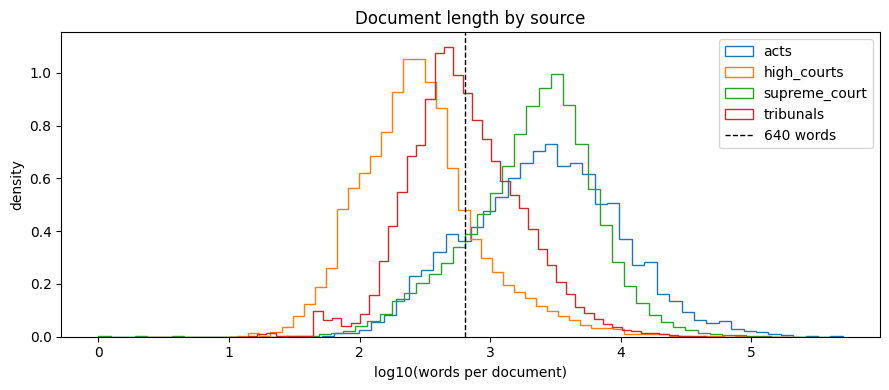


===== raw sample from acts =====
Bangalore City Planning Area Zonal Regulations (Amendment and Validation) Act, 1996 (Karnataka Act No. 2 of 1996) Statements of objects and Reasons - Act 2 of 1996. - The Bangalore City Planning Area Zonal Regulations 1972, which was in vogue till 1984, provided for construction of five floors including ground floor. The Corporation of the City of Bangalore granted permission for construction of buildings beyond five floors in certain cases. In respect of some of the buildings the permission gra

===== raw sample from high_courts =====
Court No. - 24 Case :- SECOND APPEAL No. - 550 of 1986 Appellant :- Ram Naresh Singh Baghel Respondent :- Nagar Maha Palika Lko.

Counsel for Appellant :- K.C.Jauhari,Manish Jauhari,Mohit Jauhari,Raj Kumar Srivastava,Ram Bali Ram,V.P. Mishra

Hon'ble Manish Kumar Nigam,J.

The appeal was dismissed on 09.12.1987. Thereafter, restoration application no. 846 of 1994 was also rejected on 26.10.1994. Thereafter, an applicatio

In [7]:
import matplotlib.pyplot as plt

rows = []
for name in SOURCE_NAMES:
    st = load_json(ROOT / "data" / f"{name}_stats.json")
    if not st: continue
    wcs = np.load(ROOT / "data" / f"{name}_wordcounts.npy"); wcs = wcs[wcs > 0]
    rows.append({"source": name, "GB": st["file_bytes"] / 1e9, "docs": st["docs"], "empty": st.get("empty", 0),
                 "dups": st.get("duplicates", 0), "words_M": st.get("words", 0) / 1e6,
                 "train_words_M": st.get("train_words", 0) / 1e6, "val_docs": st.get("val_docs", 0),
                 "median_words": int(np.median(wcs)) if len(wcs) else 0,
                 "p90_words": int(np.percentile(wcs, 90)) if len(wcs) else 0,
                 "chars_per_word": st.get("chars", 0) / max(st.get("words", 1), 1),
                 "raw_newline_docs": st.get("raw_has_newline", 0) / max(st["docs"], 1)})
hdr = list(rows[0].keys()) if rows else []
print(" | ".join(f"{h:>14s}" for h in hdr))
for r in rows:
    print(" | ".join(f"{v:>14.2f}" if isinstance(v, float) else f"{str(v):>14s}" for v in r.values()))
save_json(rows, ROOT / "data" / "corpus_stats_table.json")

if rows:
    plt.figure(figsize=(9, 4))
    for name in SOURCE_NAMES:
        p = ROOT / "data" / f"{name}_wordcounts.npy"
        if p.exists():
            w = np.load(p); w = w[w > 0]
            plt.hist(np.log10(w), bins=60, histtype="step", label=name, density=True)
    plt.axvline(np.log10(PROMPT_WORDS + CONT_WORDS), color="k", ls="--", lw=1, label="640 words")
    plt.xlabel("log10(words per document)"); plt.ylabel("density"); plt.legend(); plt.title("Document length by source")
    plt.tight_layout(); plt.savefig(ROOT / "figures" / "doc_length_hist.png", dpi=150); plt.show()

for name in SOURCE_NAMES:
    st = load_json(ROOT / "data" / f"{name}_stats.json")
    if st:
        print(f"\n===== raw sample from {name} =====\n{st['raw_samples'][0][:500]}")

### Which source do the test prompts resemble?
Jensen–Shannon divergence between the word distribution of the test prompts and each source's sample
(0 = identical, 1 = disjoint). Lower → that source matters more for the data mix.

In [8]:
def word_dist(texts, max_docs=None):
    c = Counter()
    for i, t in enumerate(texts):
        if max_docs and i >= max_docs: break
        c.update(w.lower() for w in re.findall(r"[A-Za-z]+", t))
    return c

def jsd(c1, c2, top=30000):
    vocab = [w for w, _ in (c1 + c2).most_common(top)]
    p = np.array([c1[w] for w in vocab], float) + 1e-9; q = np.array([c2[w] for w in vocab], float) + 1e-9
    p /= p.sum(); q /= q.sum(); m = (p + q) / 2
    kl = lambda a, b: float(np.sum(a * np.log2(a / b)))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)

def iter_sample(name, max_docs=None):
    with open(ROOT / "tok_sample" / f"{name}.jsonl", encoding="utf-8") as f:
        for i, line in enumerate(f):
            if max_docs and i >= max_docs: break
            yield json.loads(line)["text"]

if PASS1_COMPLETE:
    test_dist = word_dist(TEST_TEXTS)
    sim = {}
    for name in SOURCE_NAMES:
        sim[name] = jsd(test_dist, word_dist(iter_sample(name, 3000)))
        print(f"JSD(test, {name:14s}) = {sim[name]:.4f}")
    decisions["test_source_jsd"] = sim
    save_json(decisions, ROOT / "data" / "decisions.json")

JSD(test, acts          ) = 0.1530
JSD(test, high_courts   ) = 0.1514
JSD(test, supreme_court ) = 0.0318
JSD(test, tribunals     ) = 0.1514


## 5. Train byte-level BPE tokenizers
**Why byte-level BPE?** Every possible string is representable (no `<unk>`), case is preserved, and the library returns
character offsets for each token (needed for Phase-2 NER spans). This is the same algorithm as the assignment BPE
(repeatedly merge the most frequent adjacent pair), just implemented efficiently.
Pre-tokenisation (GPT-2 regex) splits text into words/numbers/punctuation chunks first, so merges never cross them.

We train only on the ~600 MB balanced sample: the merge list for 32k tokens is determined by fairly frequent pairs,
so more data changes almost nothing while costing much more time and RAM. The trained tokenizer is saved once
(`tokenizer.json`) and simply loaded everywhere afterwards.

In [9]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, processors

def sample_iterator():
    for name in SOURCE_NAMES:
        yield from iter_sample(name)

def train_bpe(vocab_size, out_dir):
    tok = Tokenizer(models.BPE())
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False, use_regex=True)
    tok.decoder = decoders.ByteLevel()
    tok.post_processor = processors.ByteLevel(trim_offsets=False)
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, min_frequency=2, special_tokens=SPECIAL_TOKENS,
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False)
    tok.train_from_iterator(sample_iterator(), trainer=trainer)
    out_dir.mkdir(parents=True, exist_ok=True)
    tok.save(str(out_dir / "tokenizer.json"))
    return tok

if PASS1_COMPLETE:
    sample_mb = sum(os.path.getsize(ROOT / "tok_sample" / f"{n}.jsonl") for n in SOURCE_NAMES) / 1e6
    print(f"tokenizer training sample: {sample_mb:.0f} MB")
    for V in TOKENIZER_VOCAB_SIZES:
        out = ROOT / "tokenizer" / f"bpe{V}"
        if (out / "tokenizer.json").exists():
            print(f"bpe{V}: exists, skipping"); continue
        t0 = time.time(); tok = train_bpe(V, out)
        print(f"bpe{V}: trained in {(time.time()-t0)/60:.1f} min, vocab={tok.get_vocab_size()}")
        assert tok.token_to_id("<|endoftext|>") == 0

tokenizer training sample: 535 MB
bpe16384: trained in 1.8 min, vocab=16384
bpe32768: trained in 2.1 min, vocab=32768
bpe49152: trained in 1.8 min, vocab=49152


### Compare tokenizers
* **fertility** = tokens per whitespace word (lower = shorter sequences = more text per context window and faster training)
* **prompt tokens** = how many tokens a 512-word test prompt needs → decides the minimum useful context length
* **embedding cost** = vocab × d_model parameters (with d_model = 768) that come out of the 50–300M budget
* **round-trip** = `decode(encode(x)) == x` must be 100%

In [10]:
def load_eval_candidates():
    out = []
    for n in SOURCE_NAMES:
        out += load_json(ROOT / "eval" / f"candidates_{n}.json", [])
    return out

def tokenizer_report(tok, label):
    cands = load_eval_candidates()
    rep = {"name": label, "vocab": tok.get_vocab_size()}
    for n in SOURCE_NAMES:
        texts = [c["rand_prompt"] for c in cands if c["source"] == n][:100]
        if texts:
            enc = tok.encode_batch(texts)
            rep[f"fertility_{n}"] = sum(len(e.ids) for e in enc) / sum(len(t.split()) for t in texts)
    enc = tok.encode_batch(TEST_NORM)
    lens = np.array([len(e.ids) for e in enc])
    rep["fertility_test"] = float(lens.sum() / sum(len(t.split()) for t in TEST_NORM))
    rep["test_prompt_tokens_mean"] = float(lens.mean()); rep["test_prompt_tokens_p99"] = float(np.percentile(lens, 99))
    rep["test_prompt_tokens_max"] = int(lens.max())
    rt = [tok.decode(e.ids) == t for e, t in zip(enc[:300], TEST_NORM[:300])]
    rep["roundtrip_exact"] = float(np.mean(rt))
    rep["embedding_params_M_d768"] = tok.get_vocab_size() * 768 / 1e6
    return rep

DEMO = "The appellant was convicted under Section 302 read with Section 34 of the Indian Penal Code, 1860 and Article 21 of the Constitution of India."
if PASS1_COMPLETE:
    reports = []
    for V in TOKENIZER_VOCAB_SIZES:
        tok = Tokenizer.from_file(str(ROOT / "tokenizer" / f"bpe{V}" / "tokenizer.json"))
        reports.append(tokenizer_report(tok, f"bpe{V}"))
        print(f"\nbpe{V}:", tok.encode(DEMO).tokens)
    try:
        gpt2 = Tokenizer.from_pretrained("openai-community/gpt2")   # tokenizer only (starter's choice), for comparison
        reports.append(tokenizer_report(gpt2, "gpt2 (starter)"))
        print("\ngpt2:", gpt2.encode(DEMO).tokens)
    except Exception as e:
        print("GPT-2 tokenizer comparison skipped:", e)
    keys = list(reports[0].keys())
    print()
    for k in keys:
        print(f"{k:28s}" + "".join(f"{(r.get(k) if not isinstance(r.get(k), float) else round(r.get(k), 3))!s:>18}" for r in reports))
    save_json(reports, ROOT / "tokenizer" / "tokenizer_report.json")
    decisions["main_tokenizer"] = f"bpe{MAIN_VOCAB}"
    save_json(decisions, ROOT / "data" / "decisions.json")


bpe16384: ['The', 'Ġappellant', 'Ġwas', 'Ġconvicted', 'Ġunder', 'ĠSection', 'Ġ302', 'Ġread', 'Ġwith', 'ĠSection', 'Ġ34', 'Ġof', 'Ġthe', 'ĠIndian', 'ĠPenal', 'ĠCode', ',', 'Ġ1860', 'Ġand', 'ĠArticle', 'Ġ21', 'Ġof', 'Ġthe', 'ĠConstitution', 'Ġof', 'ĠIndia', '.']

bpe32768: ['The', 'Ġappellant', 'Ġwas', 'Ġconvicted', 'Ġunder', 'ĠSection', 'Ġ302', 'Ġread', 'Ġwith', 'ĠSection', 'Ġ34', 'Ġof', 'Ġthe', 'ĠIndian', 'ĠPenal', 'ĠCode', ',', 'Ġ1860', 'Ġand', 'ĠArticle', 'Ġ21', 'Ġof', 'Ġthe', 'ĠConstitution', 'Ġof', 'ĠIndia', '.']

bpe49152: ['The', 'Ġappellant', 'Ġwas', 'Ġconvicted', 'Ġunder', 'ĠSection', 'Ġ302', 'Ġread', 'Ġwith', 'ĠSection', 'Ġ34', 'Ġof', 'Ġthe', 'ĠIndian', 'ĠPenal', 'ĠCode', ',', 'Ġ1860', 'Ġand', 'ĠArticle', 'Ġ21', 'Ġof', 'Ġthe', 'ĠConstitution', 'Ġof', 'ĠIndia', '.']


tokenizer.json: 0.00B [00:00, ?B/s]


gpt2: ['The', 'Ġappellant', 'Ġwas', 'Ġconvicted', 'Ġunder', 'ĠSection', 'Ġ302', 'Ġread', 'Ġwith', 'ĠSection', 'Ġ34', 'Ġof', 'Ġthe', 'ĠIndian', 'ĠPenal', 'ĠCode', ',', 'Ġ1860', 'Ġand', 'ĠArticle', 'Ġ21', 'Ġof', 'Ġthe', 'ĠConstitution', 'Ġof', 'ĠIndia', '.']

name                                  bpe16384          bpe32768          bpe49152    gpt2 (starter)
vocab                                    16384             32768             49152             50257
fertility_acts                           1.274             1.234             1.222             1.274
fertility_high_courts                    1.334             1.285             1.269             1.356
fertility_supreme_court                  1.247             1.205             1.191              1.25
fertility_tribunals                      1.538             1.474             1.451             1.833
fertility_test                           1.244             1.201             1.186              1.24
test_prompt_tokens_mean           

## 6. (Optional) BPE from scratch in pure Python — understanding what the library does
Byte-level BPE on a ~3 MB sample: (1) pre-tokenise with the same GPT-2 regex, (2) represent every chunk as a sequence of
byte ids 0..255, (3) repeatedly merge the most frequent adjacent pair, updating pair counts *incrementally*
(only words that contain the merged pair are touched). Then we compare with the library trained on the same sample.
Expected: nearly identical early merges (differences come from tie-breaking), and the library is orders of magnitude faster.
That speed gap is why the library is used for the 4B-token corpus.

In [11]:
try:
    import regex as _re2
    PRETOK = _re2.compile(r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+""")
except ImportError:
    PRETOK = re.compile(r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+""")

def scratch_bpe_train(texts, num_merges):
    word_freq = Counter()
    for t in texts:
        for chunk in PRETOK.findall(t):
            word_freq[chunk.encode("utf-8")] += 1
    words = [list(w) for w in word_freq]                     # each word = list of symbol ids
    freqs = list(word_freq.values())
    vocab = {i: bytes([i]) for i in range(256)}
    pair_counts, where = Counter(), defaultdict(set)
    for i, w in enumerate(words):
        for a, b in zip(w, w[1:]):
            pair_counts[(a, b)] += freqs[i]; where[(a, b)].add(i)
    merges = []
    for step in range(num_merges):
        if not pair_counts: break
        best = max(pair_counts, key=lambda p: (pair_counts[p], vocab[p[0]] + vocab[p[1]]))
        if pair_counts[best] < 2: break
        new_id = 256 + step
        vocab[new_id] = vocab[best[0]] + vocab[best[1]]
        merges.append(best)
        for i in list(where[best]):
            w, f = words[i], freqs[i]
            for a, b in zip(w, w[1:]):                         # remove this word's old pairs
                pair_counts[(a, b)] -= f
                if pair_counts[(a, b)] <= 0: del pair_counts[(a, b)]
                where[(a, b)].discard(i)
            nw, j = [], 0
            while j < len(w):                                  # apply the merge
                if j < len(w) - 1 and (w[j], w[j + 1]) == best:
                    nw.append(new_id); j += 2
                else:
                    nw.append(w[j]); j += 1
            words[i] = nw
            for a, b in zip(nw, nw[1:]):                       # add the new pairs
                pair_counts[(a, b)] += f; where[(a, b)].add(i)
        where.pop(best, None)
    return merges, vocab

def scratch_bpe_encode(text, merges):
    rank = {m: r for r, m in enumerate(merges)}
    out = []
    for chunk in PRETOK.findall(text):
        ids = list(chunk.encode("utf-8"))
        while len(ids) > 1:
            pairs = [(rank.get((a, b), 1e18), k) for k, (a, b) in enumerate(zip(ids, ids[1:]))]
            r, k = min(pairs)
            if r == 1e18: break
            ids = ids[:k] + [256 + int(r)] + ids[k + 2:]
        out.extend(ids)
    return out

def bytes_to_unicode():
    bs = list(range(ord("!"), ord("~") + 1)) + list(range(ord("¡"), ord("¬") + 1)) + list(range(ord("®"), ord("ÿ") + 1))
    cs = bs[:]; n = 0
    for b in range(256):
        if b not in bs: bs.append(b); cs.append(256 + n); n += 1
    return dict(zip(bs, map(chr, cs)))

if RUN_SCRATCH_BPE and PASS1_COMPLETE:
    texts, size = [], 0
    for t in iter_sample("supreme_court"):
        texts.append(t); size += len(t)
        if size > 3_000_000: break
    held = texts[-20:]; texts = texts[:-20]
    N_MERGES = 1000
    t0 = time.time(); merges, svocab = scratch_bpe_train(texts, N_MERGES); t_scratch = time.time() - t0
    t0 = time.time()
    lib = Tokenizer(models.BPE()); lib.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False); lib.decoder = decoders.ByteLevel()
    lib.train_from_iterator(texts, trainers.BpeTrainer(vocab_size=256 + N_MERGES, min_frequency=2, show_progress=False,
                                                        initial_alphabet=pre_tokenizers.ByteLevel.alphabet()))
    t_lib = time.time() - t0
    u2b = {v: k for k, v in bytes_to_unicode().items()}
    lib_merges = json.loads(lib.to_str())["model"]["merges"]
    lib_merges = [m.split(" ") if isinstance(m, str) else m for m in lib_merges]
    lib_merged = [bytes(u2b[c] for c in a + b) for a, b in lib_merges]
    my_merged = [svocab[a] + svocab[b] for a, b in merges]
    for K in (50, 200, len(my_merged)):
        ov = len(set(my_merged[:K]) & set(lib_merged[:K])) / K
        print(f"overlap of first {K:4d} merges (as merged strings): {ov:.1%}")
    my_tokens = sum(len(scratch_bpe_encode(t, merges)) for t in held)
    lib_tokens = sum(len(lib.encode(t).ids) for t in held)
    words = sum(len(t.split()) for t in held)
    print(f"held-out fertility  scratch: {my_tokens/words:.3f}   library: {lib_tokens/words:.3f}")
    print(f"training time       scratch: {t_scratch:.1f}s   library: {t_lib:.2f}s")
    print("first 25 scratch merges:", [svocab[a] + svocab[b] for a, b in merges[:25]])
    save_json({"n_merges": N_MERGES, "sample_chars": size, "t_scratch": t_scratch, "t_lib": t_lib,
               "fert_scratch": my_tokens / words, "fert_lib": lib_tokens / words},
              ROOT / "tokenizer" / "scratch_vs_library.json")

overlap of first   50 merges (as merged strings): 100.0%
overlap of first  200 merges (as merged strings): 100.0%
overlap of first 1000 merges (as merged strings): 100.0%
held-out fertility  scratch: 2.004   library: 2.004
training time       scratch: 6.1s   library: 0.70s
first 25 scratch merges: [b' t', b'he', b' the', b' a', b' o', b'in', b're', b'on', b'er', b'at', b' of', b'en', b'is', b'ed', b' w', b' c', b'it', b' s', b'ion', b' b', b' p', b'nd', b' in', b' to', b'or']


## 7. Local evaluation set
100 held-out windows per source (from documents the model never trains on), in exactly the official format.
Two variants because we do not know where the official prompts start:
* `start`  – the prompt is the first 512 words of a document
* `random` – the prompt starts at a random word inside the document

Look at the test-prompt beginnings printed in section 3: if they look like the beginning of judgments, prefer `start`.
Files: `eval/<mode>_prompts.json` (like test.json), `eval/<mode>_truth.json` (for the evaluator), `eval/<mode>_meta.json`.

In [12]:
if PASS1_COMPLETE:
    cands = load_eval_candidates()
    rng = random.Random(SEED)
    chosen = []
    for n in SOURCE_NAMES:
        c = [x for x in cands if x["source"] == n]; rng.shuffle(c)
        chosen += c[:EVAL_PER_SOURCE]
        print(f"{n:14s}: {len(c)} candidates -> {min(len(c), EVAL_PER_SOURCE)} chosen")
    for mode, pk, rk in [("start", "start_prompt", "start_ref"), ("random", "rand_prompt", "rand_ref")]:
        prompts, truth, meta = {}, {}, {}
        for x in chosen:
            i = f"{x['source']}_{x['doc_idx']}"
            prompts[i] = {"text": x[pk]}; truth[i] = {"text": x[rk]}; meta[i] = {"source": x["source"]}
        save_json(prompts, ROOT / "eval" / f"{mode}_prompts.json")
        save_json(truth, ROOT / "eval" / f"{mode}_truth.json")
        save_json(meta, ROOT / "eval" / f"{mode}_meta.json")
    pw = [len(v["text"].split()) for v in prompts.values()]; tw = [len(v["text"].split()) for v in truth.values()]
    print(f"eval prompts words: {min(pw)}-{max(pw)}  references words: {min(tw)}-{max(tw)}  n={len(prompts)}")

acts          : 153 candidates -> 100 chosen
high_courts   : 400 candidates -> 100 chosen
supreme_court : 400 candidates -> 100 chosen
tribunals     : 400 candidates -> 100 chosen
eval prompts words: 512-512  references words: 128-128  n=400


### Official metric (exact copy of `evaluate_phase1.py` logic) + trivial baselines
BERTScore here = `bert_score.score(lang='en')` → **roberta-large, layer 17, no idf, no baseline rescaling**.
Without rescaling, scores of any fluent English text are compressed into roughly 0.78–0.90, so
small differences (0.005) are meaningful. Baselines give us a floor the trained model must beat:
* **copy-tail**: output the last 128 words of the prompt (same topic and style, zero modelling)
* **generic**: one fixed, generic legal paragraph for every prompt

In [13]:
from collections import Counter as _C
def _lcs(a, b):
    if not a or not b: return 0
    if len(a) < len(b): a, b = b, a
    masks = {}
    for j, t in enumerate(a): masks[t] = masks.get(t, 0) | (1 << j)
    state = 0
    for t in b:
        m = masks.get(t, 0); x = m | state; y = (state << 1) | 1; state = x & ~(x - y)
    return bin(state).count("1")
def _rouge_l(p, r):
    pt, rt = p.split(), r.split()
    if not pt or not rt: return 0.0
    l = _lcs(pt, rt)
    if not l: return 0.0
    pp, rr = l / len(pt), l / len(rt); return 2 * pp * rr / (pp + rr)
def _ngr(t, n): return _C(tuple(t[i:i + n]) for i in range(len(t) - n + 1)) if len(t) >= n else _C()
def _bleu4(preds, refs):
    clipped, totals, pl, rl = [0] * 4, [0] * 4, 0, 0
    for p, r in zip(preds, refs):
        pl += len(p); rl += len(r)
        for n in range(1, 5):
            pn, rn = _ngr(p, n), _ngr(r, n); totals[n - 1] += sum(pn.values())
            for g, c in pn.items(): clipped[n - 1] += min(c, rn.get(g, 0))
    prec = [clipped[i] / totals[i] if totals[i] else 0.0 for i in range(4)]
    if any(x <= 0 for x in prec) or pl == 0: return 0.0
    bp = 1.0 if pl > rl else math.exp(1.0 - rl / pl)
    return bp * math.exp(sum(math.log(x) for x in prec) / 4)

def score_phase1(truth, pred, with_bertscore=True, per_item=False):
    ids = list(truth)
    assert set(ids) == set(pred), "ID mismatch"
    out = {"n": len(ids),
           "rougeL": sum(_rouge_l(pred[i]["text"], truth[i]["text"]) for i in ids) / len(ids),
           "bleu4": _bleu4([pred[i]["text"].split() for i in ids], [truth[i]["text"].split() for i in ids])}
    if with_bertscore:
        import bert_score, torch
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        _, _, f = bert_score.score([pred[i]["text"].strip() for i in ids], [truth[i]["text"].strip() for i in ids],
                                   lang="en", batch_size=8, verbose=False, device=dev)
        out["bertscore_f1"] = float(f.mean())
        if per_item: out["per_item_f1"] = dict(zip(ids, f.tolist()))
    return out

GENERIC = ("The learned counsel for the appellant submitted that the High Court has erred in law in not considering the "
           "evidence on record and the impugned order is liable to be set aside. On the other hand, the learned counsel for "
           "the respondent supported the order of the High Court. We have heard the learned counsel for the parties and "
           "perused the material on record. In view of the above discussion, we are of the opinion that the appeal deserves "
           "to be allowed and the impugned judgment and order passed by the High Court is set aside. The matter is remitted "
           "back to the High Court for fresh consideration in accordance with law. There shall be no order as to costs.")
GENERIC = " ".join(GENERIC.split()[:CONT_WORDS])

if PASS1_COMPLETE:
    base = load_json(ROOT / "eval" / "baselines.json", {})
    for mode in ["start", "random"]:
        prompts = load_json(ROOT / "eval" / f"{mode}_prompts.json"); truth = load_json(ROOT / "eval" / f"{mode}_truth.json")
        for bname, fn in [("copy_tail", lambda p: " ".join(p.split()[-CONT_WORDS:])), ("generic", lambda p: GENERIC)]:
            key = f"{mode}/{bname}"
            if key in base and ("bertscore_f1" in base[key] or not RUN_BERTSCORE_BASELINES): continue
            pred = {i: {"text": fn(prompts[i]["text"])} for i in prompts}
            try:
                base[key] = score_phase1(truth, pred, with_bertscore=RUN_BERTSCORE_BASELINES)
            except Exception as e:
                print("BERTScore failed (", e, ") -> lexical metrics only")
                base[key] = score_phase1(truth, pred, with_bertscore=False)
            save_json(base, ROOT / "eval" / "baselines.json")
    for k, v in base.items():
        print(f"{k:22s} " + "  ".join(f"{m}={v[m]:.4f}" for m in ("bertscore_f1", "rougeL", "bleu4") if m in v))

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

... (5 outputs left out)

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


start/copy_tail        bertscore_f1=0.8418  rougeL=0.1961  bleu4=0.0877
start/generic          bertscore_f1=0.8083  rougeL=0.1640  bleu4=0.0220
random/copy_tail       bertscore_f1=0.8421  rougeL=0.1988  bleu4=0.0845
random/generic         bertscore_f1=0.8108  rougeL=0.1686  bleu4=0.0225


## 8. Summary + optional upload
Attach this notebook's output as input to Notebook 2. If you work across accounts, set `HF_ARTIFACT_REPO`
in the setup cell and run the push below (private repo, your own artifacts only).

In [14]:
print(json.dumps(load_json(ROOT / "data" / "decisions.json"), indent=1))
print("\nfiles produced:")
for p in sorted(ROOT.rglob("*")):
    if p.is_file() and "tok_sample" not in str(p):
        print(f"  {str(p.relative_to(ROOT)):55s} {p.stat().st_size/1e6:9.2f} MB")
if HF_ARTIFACT_REPO and PASS1_COMPLETE:
    for sub in ["data", "tokenizer", "eval"]:
        hf_push(sub)

{
 "normalize": "collapse_all",
 "n_test": 1000,
 "test_words_mean": 512.0,
 "test_newline_frac": 0.0,
 "test_ends_sentence_frac": 0.045,
 "test_source_jsd": {
  "acts": 0.15299660512446128,
  "high_courts": 0.151369135762754,
  "supreme_court": 0.03184390066317039,
  "tribunals": 0.1514338003365416
 },
 "main_tokenizer": "bpe32768"
}

files produced:
  data/acts_dups.npy                                           0.00 MB
  data/acts_hashes.npy                                         0.15 MB
  data/acts_stats.json                                         0.00 MB
  data/acts_wordcounts.npy                                     0.08 MB
  data/corpus_stats_table.json                                 0.00 MB
  data/decisions.json                                          0.00 MB
  data/files.json                                              0.00 MB
  data/high_courts_dups.npy                                    0.95 MB
  data/high_courts_hashes.npy                                 20.29 MB
  data/